In [69]:
""" Classification """

# Logistic Regression, LDA, QDA, and KNN
# The Stock Market Data

# Smarket data = set consist of percentage returns for the S&P500 stock index over 1250 days from 2001 untill 2005.
# Lag1 -> Lag5 the five previous trading days
# Volumne = the number of shares traded on the previouss day in billions.
# today = the percentage return on the date in question.
# Direction = whether the market was up or Down on this date.

' Classification '

In [70]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS, summarize)
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [71]:
# Load the smarket data

Smarket = load_data('Smarket')
Smarket

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,2001,0.381,-0.192,-2.624,-1.055,5.010,1.19130,0.959,Up
1,2001,0.959,0.381,-0.192,-2.624,-1.055,1.29650,1.032,Up
2,2001,1.032,0.959,0.381,-0.192,-2.624,1.41120,-0.623,Down
3,2001,-0.623,1.032,0.959,0.381,-0.192,1.27600,0.614,Up
4,2001,0.614,-0.623,1.032,0.959,0.381,1.20570,0.213,Up
...,...,...,...,...,...,...,...,...,...
1245,2005,0.422,0.252,-0.024,-0.584,-0.285,1.88850,0.043,Up
1246,2005,0.043,0.422,0.252,-0.024,-0.584,1.28581,-0.955,Down
1247,2005,-0.955,0.043,0.422,0.252,-0.024,1.54047,0.130,Up
1248,2005,0.130,-0.955,0.043,0.422,0.252,1.42236,-0.298,Down


In [72]:
# A truncated listing of the data,
# check the vatiables name

Smarket.columns

Index(['Year', 'Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today',
       'Direction'],
      dtype='str')

In [73]:
# compute the correlation matrix using the corr() method for data frames,
# Which produces a matrix that contains all of the pairwise correlations among the variables.
# The 'pandas' library not gonna report a correlation for the 'Direction' variable because it is qualitative.

Smarket.corr(numeric_only=True)

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000000,0.029700,0.030596,0.033195,0.035689,0.029788,0.539006,0.030095
Lag1,0.029700,1.000000,-0.026294,-0.010803,-0.002986,-0.005675,0.040910,-0.026155
Lag2,0.030596,-0.026294,1.000000,-0.025897,-0.010854,-0.003558,-0.043383,-0.010250
Lag3,0.033195,-0.010803,-0.025897,1.000000,-0.024051,-0.018808,-0.041824,-0.002448
Lag4,0.035689,-0.002986,-0.010854,-0.024051,1.000000,-0.027084,-0.048414,-0.006900
Lag5,0.029788,-0.005675,-0.003558,-0.018808,-0.027084,1.000000,-0.022002,-0.034860
Volume,0.539006,0.040910,-0.043383,-0.041824,-0.048414,-0.022002,1.000000,0.014592
Today,0.030095,-0.026155,-0.010250,-0.002448,-0.006900,-0.034860,0.014592,1.000000


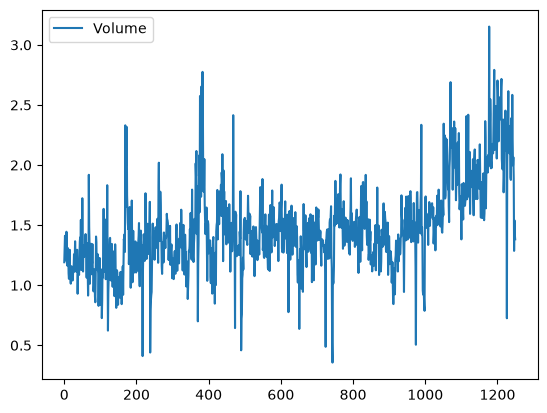

In [74]:
# The correlation close to zero
# The only substantial correlation is between 'Year' and 'Volume'
# The average number of shares traded daily increased from 2001 to 2005

Smarket.plot(y='Volume');

In [75]:
""" Logistic Regression"""

# sm.GLM() function fits 'generalized linear models, a class of models that includes logistic regression.
# sm.Logit() fits a logistic regression model directly.
# family=sm.families.Binomial() in order to tell statsmodels to run a logistic regression rather than some other type of generalized linear model.

allvars = Smarket.columns.drop(['Today', 'Direction', 'Year'])
design = MS(allvars)
X = design.fit_transform(Smarket)
y = Smarket.Direction == 'Up'
glm = sm.GLM(y,
             X,
             family=sm.families.Binomial())
results = glm.fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,-0.1260,0.241,-0.523,0.601
Lag1,-0.0731,0.050,-1.457,0.145
Lag2,-0.0423,0.050,-0.845,0.398
Lag3,0.0111,0.050,0.222,0.824
Lag4,0.0094,0.050,0.187,0.851
Lag5,0.0103,0.050,0.208,0.835
Volume,0.1354,0.158,0.855,0.392


In [76]:
# The smallest p-value is assiciated with Lag1
# The nagative coefficient for this predictor suggests that if the market had a positive return yesterday, then it is less likely to go up today.
# A value of 0.15, the p-value is still relatively large, and so there is no clear evidence of a real association between Lag1 and Direction.

# use the 'params' attribute of results in order to access just the coefficients for this fitted model.

results.params

intercept   -0.126000
Lag1        -0.073074
Lag2        -0.042301
Lag3         0.011085
Lag4         0.009359
Lag5         0.010313
Volume       0.135441
dtype: float64

In [77]:
# pvalues = to access the p-values for the coefficients

results.pvalues

intercept    0.600700
Lag1         0.145232
Lag2         0.398352
Lag3         0.824334
Lag4         0.851445
Lag5         0.834998
Volume       0.392404
dtype: float64

In [78]:
# predict() method of results can be used to predict the probability that the market will go up, given values of the predictors.
# If no data set is supplied to the predict() function, then the probabilities are computed for the training data that was used to fit the logistic regression model.

probs = results.predict()
probs[:10]

array([0.50708413, 0.48146788, 0.48113883, 0.51522236, 0.51078116,
       0.50695646, 0.49265087, 0.50922916, 0.51761353, 0.48883778])

In [79]:
# convert these predicted probabilities into class labels, Up or Down.

labels = np.array(['Down'] * 1250)
labels[probs>0.5] = "Up"

In [80]:
# The confusion_table() function summarizes thee predictions, showing how many observations were correctly or incorrectly classified.
# sklearn.metrices transposes the resulting matrix and includes row and column labels.

confusion_table(labels, Smarket.Direction)

Truth,Down,Up
Predicted,,
Down,145,141
Up,457,507


In [81]:
# Our model predicted that the market would go up on 507 days and that it would go down on 145 days,
# for a total of 507 + 145 = 652 correct predictions.
# np.mean() function can be used to compute the fraction of days for which the prediction was correct.

(507+145)/1250, np.mean(labels == Smarket.Direction)

(0.5216, np.float64(0.5216))

In [82]:
# Logistics regression correctly predicted the movement of the market 52.5% of the time
# But we tested the model on the same set of 1,250 observations.
# in other words, 100 - 52.2 = 47.8% is the training error rate.

# The training error rate is often overly optimistic it tends to understimate the test error late.
# we can fit the model using the accurate data then examine how well it predicted the held of data.

# Let's create a Boolean vector corresponding to the observation from 2001 through 2004.
# Use this vector to create a held out data set of observations from 2005

train = (Smarket.Year < 2005)
Smarket_train = Smarket.loc[train]
Smarket_test = Smarket.loc[~train]
Smarket_test.shape

(252, 9)

In [83]:
# Boolean arrays can be used to obtain a subset of the rows or columns of a data frame using the loc method.
# The ~ can be used to negate all of the elements of train are true.
# Smarket.loc[~train] yields a subset of the rows of the data frame of the stock market data containing only the observations for which train is False.

# We now fit a logistic regression model using only the subset of the observation that correspond to dates before 2005.
# then obtain predicted probabilities of the stock market going up for each of the days in our test set.

X_train, X_test = X.loc[train], X.loc[~train]
y_train, y_test = y.loc[train], y.loc[~train]
glm_train = sm.GLM(y_train,
                   X_train,
                   family=sm.families.Binomial())
results = glm_train.fit()
probs = results.predict(exog=X_test)

In [84]:
# prediction for 2005 to the actual movements of the market over that time period.

D = Smarket.Direction
L_train, L_test = D.loc[train], D.loc[~train]

In [85]:
# threshold the fitted probability at 50% to form our predicted labels

labels = np.array(['Down'] * 252)
labels[probs>0.5] = 'Up'
confusion_table(labels, L_test)

Truth,Down,Up
Predicted,,
Down,77,97
Up,34,44


In [86]:
# The test accuracy is around 48% while the error rate is about 52%

np.mean(labels == L_test), np.mean(labels != L_test)

(np.float64(0.4801587301587302), np.float64(0.5198412698412699))

In [87]:
# != notations means not equal to., and so that the last command computes the test set error rate.
# using predictors that have no relationship with the response tends to cause a deterioration in the test error rate
# Remove that predictors may in turn yield an improvement.

model = MS(['Lag1', 'Lag2']).fit(Smarket)
X = model.transform(Smarket)
X_train, X_test = X.loc[train], X.loc[~train]
glm_train = sm.GLM(y_train,
                   X_train,
                   family=sm.families.Binomial())
results = glm_train.fit()
probs = results.predict(exog=X_test)
labels = np.array(['Down'] * 252)
labels[probs>0.5] = 'Up'
confusion_table(labels, L_test) 

Truth,Down,Up
Predicted,,
Down,35,35
Up,76,106


In [88]:
# Let's evaluate the overall accuracy a well as the accuracy within the days when logsitic regresion precits the increase

(35+106) / 252, 106/ (106+76)

(0.5595238095238095, 0.5824175824175825)

In [89]:
# What if I want to precit the returns associated with particular values of Lag1 and Lag2?

newdata = pd.DataFrame({'Lag1' : [1.2, 1.5],
                        'Lag2' : [1.1, -0.8]});
newX = model.transform(newdata)
results.predict(newX)

0    0.479146
1    0.496094
dtype: float64

In [90]:
""" Linear Discriminant Analysis """

# LDA = LinearDiscriminantAnalysis()

lda = LDA(store_covariance=True)

In [91]:
# Directly use the labels rather than the Boolean vectors y_train

X_train, X_test = [M.drop(columns=['intercept'])
                   for M in [X_train, X_test]]
lda.fit(X_train, L_train)

,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[<U4](2,)","['Down','Up']"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](1, 2)","[[-0.06,-0.04]]"
"covariance_ covariance_: array-like of shape (n_features, n_features)Weighted within-class covariance matrix. It corresponds to`sum_k prior_k * C_k` where `C_k` is the covariance matrix of thesamples in class `k`. The `C_k` are estimated using the (potentiallyshrunk) biased estimator of covariance. If solver is 'svd', onlyexists when `store_covariance` is True.","ndarray[float64](2, 2)","[[ 1.51,-0.03], [-0.03, 1.51]]"


In [92]:
lda.means_

# Extract the meand in the 2 classes with the means attribute.

array([[ 0.04279022,  0.03389409],
       [-0.03954635, -0.03132544]])

In [93]:
# We can be sure of which entry corresponds to which label by looking at the classes_ attribute

lda.classes_

array(['Down', 'Up'], dtype='<U4')

In [94]:
# check down and up
lda.priors

In [95]:
lda.scalings_

array([[-0.64266332],
       [-0.51404461]])

In [96]:
# The linear combination of Lag1 and Lag2 that are used to form the LDA decision rule.

lda_pred = lda.predict(X_test)

In [97]:
# The LDA and logsitic regression are slmost identical

confusion_table(lda_pred, L_test)

Truth,Down,Up
Predicted,,
Down,35,35
Up,76,106


In [98]:
# applying a 50% threshold to the posterior probabilities of the being in class one allows us to recreate the predictions contained in lda_pred.

lda_prob = lda.predict_proba(X_test)
np.all(
    np.where(lda_prob[:,1] >= 0.5, 'Up', 'Down') == lda_pred
)

np.True_

In [99]:
np.all(
    [lda.classes_[i] for i in np.argmax(lda_prob, 1)] == lda_pred
)

np.True_

In [100]:
np.sum(lda_prob[:, 0] > 0.9)

np.int64(0)

In [101]:
""" Quadratic Discriminant Analysis """

# QDA = implemented via QuadraticDiscriminantAnalysis() 

qda = QDA(store_covariance=True)
qda.fit(X_train, L_train)

,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",True
,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Unique class labels.","ndarray[object](2,)","['Down','Up']"
"covariance_ covariance_: list of len n_classes of ndarray of shape (n_features, n_features)For each class, gives the covariance matrix estimated using thesamples of that class. The estimates use the maximum likelihood(biased) covariance estimator. Only present if `store_covariance` isTrue.",list,"[array([[ 1.50... 1.53246749]]), array([[ 1.51... 1.48732877]])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Lag1','Lag2']"


In [102]:
# QDA() = will again compute means_ and priors_

qda.means_, qda.priors_

(array([[ 0.04279022,  0.03389409],
        [-0.03954635, -0.03132544]]),
 array([0.49198397, 0.50801603]))

In [103]:
# QDA() = classifier will estimate one covatiance per class

qda.covariance_[0]

array([[ 1.50355429, -0.03916813],
       [-0.03916813,  1.53246749]])

In [104]:
# It does not contain the coefficients of the linear discriminants,
# the QDA classifier involves a quadratic

qda_pred = qda.predict(X_test)
confusion_table(qda_pred, L_test)

Truth,Down,Up
Predicted,,
Down,30,20
Up,81,121


In [105]:
np.mean(qda_pred == L_test)

np.float64(0.5992063492063492)

In [106]:
""" Native Bayes """

# GaussianNB() of the naive Bayes classifier models each quantitative feature using a Gaussian distribution.

NB = GaussianNB()
NB.fit(X_train, L_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[491.,507.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.49,0.51]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U4](2,)","['Down','Up']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.511e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Lag1','Lag2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[ 0.04, 0.03], [-0.04,-0.03]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[1.5 ,1.53], [1.51,1.49]]"


In [107]:
NB.classes_

array(['Down', 'Up'], dtype='<U4')

In [109]:
# The class prior probabilities are stored in the class_prior_ attribute

NB.class_prior_

array([0.49198397, 0.50801603])

In [113]:
# The parameters of the features can be found in the theta_ and var_
NB.theta_

array([[ 0.04279022,  0.03389409],
       [-0.03954635, -0.03132544]])

In [112]:
# Its variance = 1.503

NB.var_

array([[1.50355429, 1.53246749],
       [1.51401364, 1.48732877]])

In [114]:
# We can easily varify the mean computation:

X_train[L_train == 'Down'].mean()

Lag1    0.042790
Lag2    0.033894
dtype: float64

In [115]:
# Similarly fo the variance

X_train[L_train == 'Down'].var(ddof=0)

Lag1    1.503554
Lag2    1.532467
dtype: float64

In [118]:
# The GaussianNB() function calculates variances using the 1/n formula.

nb_labels = NB.predict(X_test)
confusion_table(nb_labels, L_test)

Truth,Down,Up
Predicted,,
Down,29,20
Up,82,121


In [119]:
# estimates the probablitiy that each observation belongs to a particular class.

NB.predict_proba(X_test)[:5]

array([[0.4873288 , 0.5126712 ],
       [0.47623584, 0.52376416],
       [0.46529531, 0.53470469],
       [0.47484469, 0.52515531],
       [0.49020587, 0.50979413]])

In [ ]:
""" K-Nearest Neighbors """

